Signal purity is 25.8
Candidate with the highest transverse momentum is {rho: 4.42e+03, phi: -0.419, eta: -0.408, tau: 87.2}. Its transerve momemntum is: 4422.92,
 mass is: 87.24


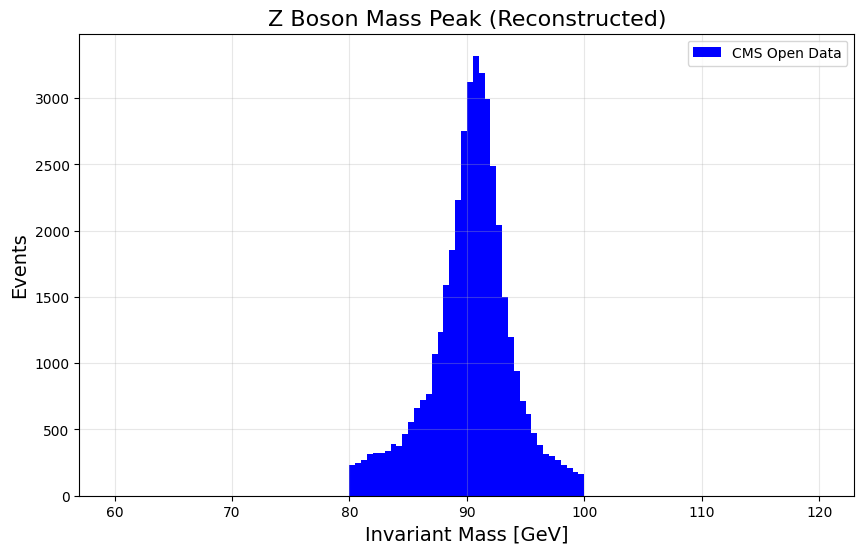

In [5]:
import uproot
import vector
import awkward as ak
import matplotlib.pyplot as plt
import numpy 

file= uproot.open('DoubleMu.root')
tree= file['Events']

arrays= tree.arrays(['Muon_mass', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge'], library = 'ak')

muons= vector.zip({'mass': arrays['Muon_mass'], 
                   'pt': arrays['Muon_pt'], 
                   'eta': arrays['Muon_eta'], 
                   'phi': arrays['Muon_phi'], 
                   'charge': arrays['Muon_charge'] })

pair_mask= ak.num(muons) >= 2
z_cand= muons[pair_mask]

mu1= z_cand[:, 0]
mu2= z_cand[:, 1]

charge_mask= mu1.charge != mu2.charge
mu1= mu1[charge_mask]
mu2= mu2[charge_mask]

z_boson= mu1 + mu2

mass_mask= (z_boson.mass > 80) & (z_boson.mass < 100)
z_sig= z_boson[mass_mask]

n_total= len(z_boson)
n_signal= len(z_sig)
purity = (n_signal/n_total)*100
print(f'Signal purity is {purity:.1f}')

best_idx= ak.argmax(z_sig.pt)
candidate= z_sig[best_idx]

print(f'Candidate with the highest transverse momentum is {candidate}. Its transerve momemntum is: {candidate.pt:.2f},\n mass is: {candidate.mass:.2f}')

plt.figure(figsize=(10,6))
plt.hist(z_sig.mass, bins=120, range=(60, 120), histtype='stepfilled', color='blue', label='CMS Open Data')
plt.title("Z Boson Mass Peak (Reconstructed)", fontsize=16)
plt.xlabel("Invariant Mass [GeV]", fontsize=14)
plt.ylabel("Events", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("z_peak_portfolio.png")
plt.show()

Number of sigma candidates found is: 169


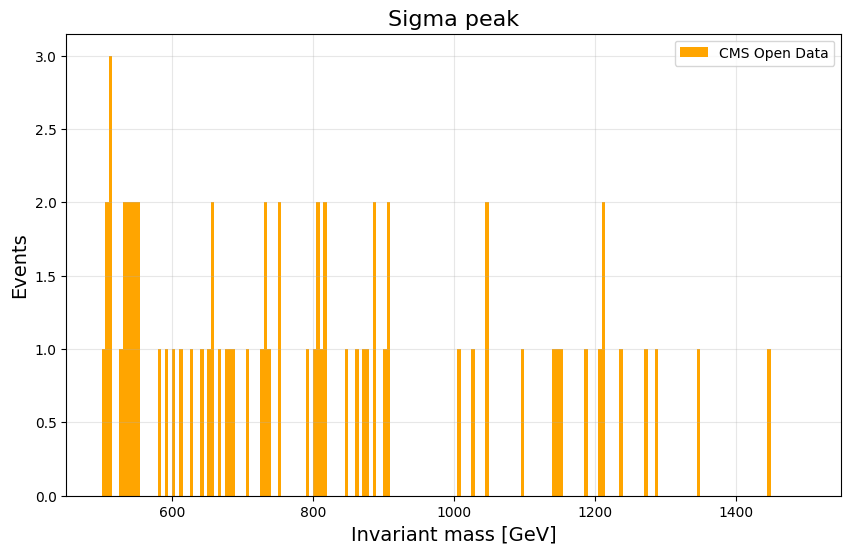

In [6]:
import uproot 
import vector
import awkward as ak 
import matplotlib.pyplot as plt
import numpy 

file= uproot.open('DoubleMu.root')
tree= file['Events']

arrays= tree.arrays(['Muon_mass', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge'], library = 'ak')

muons= vector.zip({'mass': arrays['Muon_mass'], 
                   'pt': arrays['Muon_pt'], 
                   'eta': arrays['Muon_eta'], 
                   'phi': arrays['Muon_phi'], 
                   'charge': arrays['Muon_charge'] })

pair_mask= ak.num(muons) >= 3
signal_cand= muons[pair_mask]

mu1= signal_cand[:, 0]
mu2= signal_cand[:, 1]
mu3= signal_cand[:, 2]

charge_mask1= (mu1.charge != mu2.charge) | (mu1.charge != mu3.charge) #All 3 cannot have the same charge as 2 come from Z boson decay 
mu1= mu1[charge_mask1]
mu2= mu2[charge_mask1]
mu3= mu3[charge_mask1]

energy_mask= (mu1.pt + mu2.pt + mu3.pt) > 500
mu1= mu1[energy_mask]
mu2= mu2[energy_mask]
mu3= mu3[energy_mask]

#Here I am applying the Z boson filter criteria to filter out those mu2 and mu3 which do not arise from Z boson decay

charge_mask2= mu2.charge != mu3.charge
mu1= mu1[charge_mask2]
mu2= mu2[charge_mask2]
mu3= mu3[charge_mask2]

sig_z_cand= mu2 + mu3
mass_mask= (sig_z_cand.mass>80) & (sig_z_cand.mass<100)
sig_z= sig_z_cand[mass_mask]
mu1= mu1[mass_mask]

sigma= mu1 + sig_z

print(f'Number of sigma candidates found is: {len(sigma)}')

plt.figure(figsize=(10,6))
plt.hist(sigma.mass, bins=200, range=(500,1500), histtype='stepfilled', color= 'orange', label= 'CMS Open Data') 
plt.title('Sigma peak', fontsize=16)
plt.xlabel('Invariant mass [GeV]', fontsize= 14)
plt.ylabel('Events', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('sigma_peak.png')
plt.show()